In [91]:
import sys
import os
from pathlib import Path

def find_project_root(start):
    for base in [start, *start.parents]:
        for candidate in [base, base / "barrier-extraction"]:
            if (candidate / "src").is_dir() and (candidate / "data").is_dir():
                return candidate
    raise FileNotFoundError("Could not locate barrier-extraction project root containing src/ and data/.")

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data"
PLOT_DIR = PROJECT_ROOT / "plots"
PLOT_DIR.mkdir(exist_ok=True)
EXPERIMENT_DATA_DIR = DATA_DIR / "experimental"


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.wong import sigma
from src.plot import plot_D_f
#from src.utils import compute_peak_metrics

try:
    import scienceplots
    plt.style.use(["science", "notebook", "ieee", "grid"])
except ModuleNotFoundError:
    plt.style.use('default')

import scipy as sp
from scipy.optimize import curve_fit
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, Matern, ConstantKernel, ExpSineSquared, RationalQuadratic
import findiff as fd



plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.labelsize": 18,
    "axes.titlesize": 17,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 10,
    "mathtext.fontset": "cm",  # use Computer Modern math
    "axes.linewidth": 1.2,
    "lines.linewidth": 2.0,
})

save_data = True # Toggle to True to overwrite generated .npy training data


<>:13: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:13: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/tmp/ipykernel_2869370/4274595202.py:13: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  tmpdf = pd.read_csv(os.path.join(dirname,file),sep='\s+',names=['Ecm','Sigma','Error'])


Best-fit parameters:
  E0    = 73.3846 ± 0.0047 MeV
  R0    = 10.2260 ± 0.0078 fm
  hbarw = 4.8410 ± 0.0074 MeV


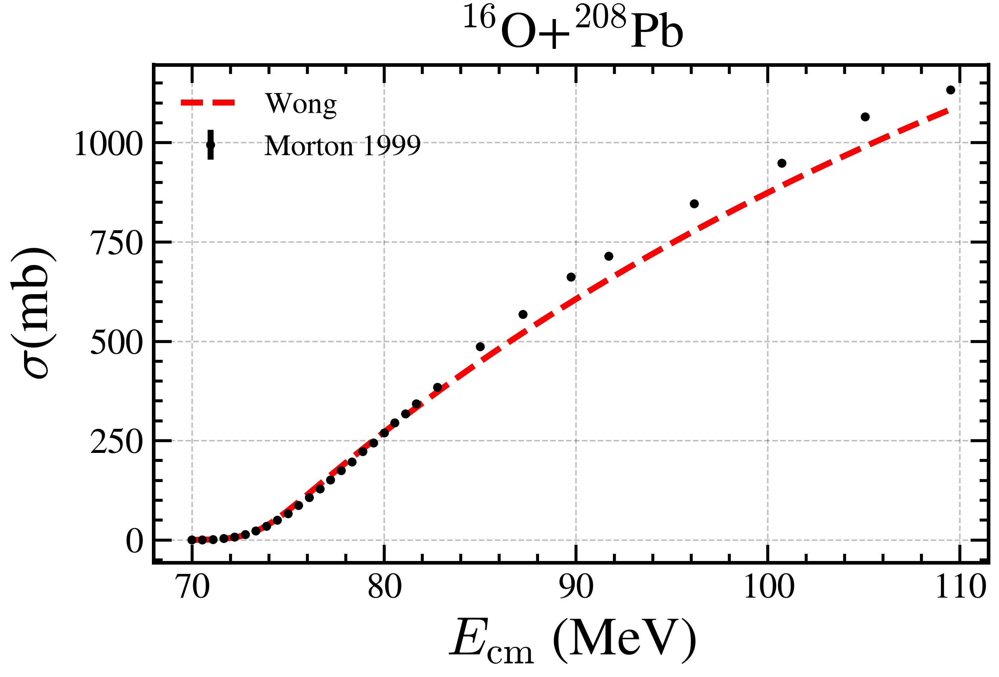

In [92]:
dirname = EXPERIMENT_DATA_DIR / "16O208Pb_exp"
system = "$^{208}$Pb+$^{16}$O"
fileprefix = dirname

expfiles = [ 'expMort.dat', 'expDas.dat' ]
explabel = [ 'Morton et al. 1999', 'Dasgupta et al. 2007' ]
expmarker = [ 'o', 's' ]
expcolor = [ 'k', 'g' ]

exp = []

for file in expfiles:
    tmpdf = pd.read_csv(os.path.join(dirname,file),sep='\s+',names=['Ecm','Sigma','Error'])
    if(tmpdf['Ecm'].iloc[0] > tmpdf['Ecm'].iloc[-1]):
        exp.append(tmpdf.iloc[::-1])
    else:
        exp.append(tmpdf)

xmin = 70.0
xmax = 90.0


E_data = exp[0]['Ecm'].to_numpy()
Sigma_data = exp[0]['Sigma'].to_numpy()
Sigma_err  = exp[0]['Error'].to_numpy()


# --- Initial guesses for [E0, R0, hbarw] ---
# You may need to tweak these based on the fitted reaction system.
initial_guess = [70.0, 11.0, 4]

# --- Perform the fit ---
popt, pcov = curve_fit(
    sigma,
    E_data,
    Sigma_data,
    p0=initial_guess,
    sigma=Sigma_err,
    absolute_sigma=True,
    # bounds can help keep parameters physical:
    bounds=([0.0, 8.0, 0.0], [np.inf, 15.0, np.inf])
)

E0_opt, R0_opt, hbarw_opt = popt
perr = np.sqrt(np.diag(pcov))

print(f"Best-fit parameters:")
print(f"  E0    = {E0_opt:.4f} ± {perr[0]:.4f} MeV")
print(f"  R0    = {R0_opt:.4f} ± {perr[1]:.4f} fm")
print(f"  hbarw = {hbarw_opt:.4f} ± {perr[2]:.4f} MeV")

# --- Plot experiment vs. fit ---
E_plot = np.linspace(E_data.min(), E_data.max(), 500)
Sigma_fit = sigma(E_plot, E0_opt, R0_opt, hbarw_opt)

plt.figure(figsize=(5,3))
plt.errorbar(E_data, Sigma_data, yerr=Sigma_err, fmt='o', label='Morton 1999', markersize=2)
#plt.scatter(E_data, Sigma_data, label='Morton 1999', color='k', s=10)
plt.plot(E_plot, Sigma_fit, label='Wong', linewidth=2)
plt.xlabel(r'$E_{\mathrm{cm}}$ (MeV)')
plt.ylabel(r'$\sigma$(mb)')
plt.title("$^{16}$O+$^{208}$Pb")
#plt.yscale('log')
plt.legend(frameon=False)
plt.grid(True, alpha=0.25)
plt.savefig("../../plots/WongChisquaredFit_16O208Pb.png", dpi=300, bbox_inches='tight', pad_inches=0.25)
#plt.tight_layout()
plt.show()

In [93]:
#from src.train import train_gp
from src.plot import plot_gp_with_data
from src.utils import barrier_dist, paper_three_point_barrier

def train_gp(E_train, sigma_mu_train, sigma_var_train, n_restarts=20, kernel=None, noise=None, log=False):
    """
    Train a Gaussian Process on 1D data with heteroscedastic noise.

    Parameters
    ----------
    E_train : array-like, shape (N,)
        Training energies.
    sigma_mu_train : array-like, shape (N,)
        Observed cross-section values at E_train. In log mode these must be positive.
    sigma_var_train : array-like, shape (N,)
        Linear-space observation variances for the cross-section values.
    n_restarts : int, optional (default=20)
        Number of restarts for the optimizer.
    kernel : sklearn kernel, optional
        Kernel to use. If omitted, an RBF kernel is built and an optional WhiteKernel is added.
    noise : bool, optional
        If true and kernel is omitted, add a fitted WhiteKernel term.
    log : bool, optional
        If true, fit log(sigma_mu_train) with delta-method variances sigma_var_train/sigma_mu_train**2.

    Returns
    -------
    gp : GaussianProcessRegressor
        The fitted GP model.
    """
    # 1) Sort E_train for length-scale estimation
    E_sorted = np.sort(np.asarray(E_train))
    dE = np.diff(E_sorted)
    ell0 = min(np.abs(dE))
    lbound, ubound = ell0 , 10.0

    # 2) Print the empirical variance as a quick diagnostic.
    var_y0 = np.var(sigma_mu_train)
    print(var_y0)

    if kernel is None:
        # 3) Build an RBF kernel, optionally adding a fitted WhiteKernel.
        k_rbf   = 1.0*RBF(length_scale=1.0, length_scale_bounds=(lbound, ubound))#ConstantKernel() length_scale_bounds=(lbound, ubound)) # *ConstantKernel(constant_value=var_y0, constant_value_bounds=(var_y0/100, var_y0*100)) 
        kernel  = k_rbf
        if noise: 
            k_noise = WhiteKernel(noise_level=1e-5 , noise_level_bounds=(1e-9, 1e-3))
            kernel  += k_noise

    if log: 
        gp = GaussianProcessRegressor(
            kernel=kernel,
            alpha= sigma_var_train / sigma_mu_train**2,
            normalize_y=False,
            n_restarts_optimizer=n_restarts
        )
        gp.fit(np.asarray(E_train).reshape(-1, 1), np.log(np.asarray(sigma_mu_train)))
    else:
        gp = GaussianProcessRegressor(
            kernel=kernel,
            alpha=sigma_var_train,
            normalize_y=False,
            n_restarts_optimizer=n_restarts
        )
        gp.fit(np.asarray(E_train).reshape(-1, 1), np.asarray(sigma_mu_train))

    return gp

# ---------- Residual summary table ----------
def summarize(err):
    if err.size == 0:
        return dict(n=0, mean=np.nan, std=np.nan, median=np.nan, MAE=np.nan, RMSE=np.nan,
                    min=np.nan, max=np.nan)
    return dict(
        n      = int(err.size),
        mean   = float(np.mean(err)),
        std    = float(np.std(err, ddof=1)) if err.size > 1 else 0.0,
        median = float(np.median(err)),
        MAE    = float(np.mean(np.abs(err))),
        RMSE   = float(np.sqrt(np.mean(err**2))),
        min    = float(np.min(err)),
        max    = float(np.max(err)),
    )

def symmetric_bins(err, bins=30, clip_percentiles=(1, 99)):
    """Symmetric bin edges around 0 using robust percentiles."""
    if err.size == 0:
        return np.linspace(-1, 1, bins + 1)
    lo, hi = np.percentile(err, clip_percentiles)
    rng = max(abs(lo), abs(hi), 1e-12)
    return np.linspace(-rng, rng, bins + 1)

# ---------- LaTeX figure helpers ----------
TRUE_COLOR = "tab:blue"
BARRIER_TRUE_COLOR = "black"
GP_COLOR = "tab:purple"
DATA_COLOR = "0.15"
BAND_ALPHA = 0.22
DATA_BAND_ALPHA = 0.10
SHARED_LABEL_FONTSIZE = 24
SHARED_XLABEL_Y = 0.06
SHARED_YLABEL_X = 0.1


def format_eta(ratio):
    e = int(np.floor(np.log10(ratio)))
    m = ratio / 10**e
    if np.isclose(m, 1.0):
        return rf"$\eta = 10^{{{e}}}$"
    return rf"$\eta = {m:.1f}\times 10^{{{e}}}$"


def add_panel_label(ax, label, loc="upper left"):
    if loc == "lower left":
        x, y, va = 0.03, 0.08, "bottom"
    else:
        x, y, va = 0.03, 0.92, "top"
    ax.text(
        x,
        y,
        label,
        transform=ax.transAxes,
        ha="left",
        va=va,
        fontsize=11,
    )


def sigma_barrier_legend_handles():
    handles = [
        plt.Line2D([], [], color=TRUE_COLOR, lw=2.0, label="True"),
        plt.Line2D([], [], color=GP_COLOR, lw=2.0, ls="--", label="GP mean"),
        plt.Rectangle((0, 0), 1, 1, color=GP_COLOR, alpha=BAND_ALPHA, label=r"GP $\pm1.96$ SD"),
        plt.Line2D([], [], marker="o", color=DATA_COLOR, lw=0, markersize=4, label="Training energies"),
    ]
    return handles



def choose_three_point_stencil(E_train, target_step=2.5):
    E_train = np.asarray(E_train, dtype=float)
    candidates = []
    for stencil in range(1, max(1, E_train.size // 2)):
        if 2 * stencil >= E_train.size:
            continue
        delta_energy = (E_train[2 * stencil:] - E_train[:-2 * stencil]) / 2.0
        avg_step = float(np.nanmean(delta_energy))
        if np.isfinite(avg_step):
            candidates.append((abs(avg_step - target_step), stencil, avg_step))
    if not candidates:
        raise ValueError("No complete three-point stencil is available")
    _, stencil, avg_step = min(candidates, key=lambda item: item[0])
    return stencil, avg_step


def plot_three_point_estimate(ax, E_train, sigma_train, sigma_var_train, *, ms=3.5, print_label=None):
    sigma_err = np.sqrt(np.asarray(sigma_var_train, dtype=float))
    stencil, avg_step = choose_three_point_stencil(E_train)
    if print_label is not None:
        print(f"{print_label}: 3-point stencil={stencil}, average Delta E = {avg_step:.2f} MeV")
    E_barrier, dist, err = paper_three_point_barrier(
        E_train, sigma_train, sigma_err, dE=stencil
    )
    finite_err = np.isfinite(err) & (err > 0)
    if np.all(finite_err):
        return ax.errorbar(
            E_barrier,
            dist,
            yerr=err,
            fmt="o",
            color=DATA_COLOR,
            ms=ms,
            lw=1,
            capsize=2,
            label="3-point",
            zorder=5,
        )
    return ax.plot(
        E_barrier,
        dist,
        marker="o",
        ls="",
        color=DATA_COLOR,
        ms=ms,
        label="3-point",
        zorder=5,
    )[0]


def barrier_legend_handles(three_point_handle=None):
    handles = [
        plt.Line2D([], [], color=BARRIER_TRUE_COLOR, lw=2.0, label="True"),
        plt.Line2D([], [], color=GP_COLOR, lw=2.0, ls="--", label="GP mean"),
        plt.Rectangle((0, 0), 1, 1, color=GP_COLOR, alpha=BAND_ALPHA, label=r"GP $\pm1.96$ SD"),
    ]
    if three_point_handle is not None:
        handles.append(three_point_handle)
    return handles


def add_inset_legend(ax, handles, ncol=1):
    ax.legend(
        handles=handles,
        loc="upper right",
        bbox_to_anchor=(0.98, 0.98),
        bbox_transform=ax.transAxes,
        ncol=ncol,
        frameon=False,
        fontsize=9,
        handlelength=1.6,
        borderpad=0.35,
        labelspacing=0.3,
        columnspacing=0.8,
    )


def plot_sigma_barrier_grid(results_dict, outfile, suptitle=None):
    items = list(results_dict.items())[:8]
    nrows, ncols = len(items), 2
    fig, axes = plt.subplots(nrows, ncols, figsize=(7.2, 2.35 * nrows), sharex="col")
    axes = np.asarray(axes).reshape(nrows, ncols)
    y_true_sigma = sigma(E_eval, E0_opt, R0_opt, hbarw_opt)

    for row, (_, data) in enumerate(items):
        E_train_local = data.get("E_train", E_train)
        mu = data["mu"]
        std = data["std"]
        samples = data["samples"]
        ratio = data["ratio"]
        alpha = data.get("alpha")
        sigma_train_noisy = data.get("sigma_train_noisy", sigma_train)
        row_label = format_eta(ratio)

        ax_sigma = axes[row, 0]
        ax_barrier = axes[row, 1]

        ax_sigma.plot(E_eval, y_true_sigma, lw=2.0, color=TRUE_COLOR)
        ax_sigma.plot(E_eval, mu, lw=2.0, ls="--", color=GP_COLOR)
        # Pointwise GP predictive mean plus/minus 1.96 posterior standard deviations.
        ax_sigma.fill_between(E_eval, mu - 1.96 * std, mu + 1.96 * std, color=GP_COLOR, alpha=BAND_ALPHA, linewidth=0)
        ax_sigma.scatter(E_train_local, sigma_train_noisy, s=8, color=DATA_COLOR, alpha=0.8, edgecolor="none", zorder=5)
        add_panel_label(ax_sigma, row_label)
        ax_sigma.set_xlim(E_eval[0], E_eval[-1])
        ax_sigma.grid(True, alpha=0.25)
        ax_sigma.tick_params(labelsize=11)

        barrier_E = data.get("barrier_E", E_fine)
        ax_barrier.plot(E_fine, true_d, lw=2.0, color=TRUE_COLOR)
        d_samples = np.stack([barrier_dist(barrier_E, samples[:, j], acc=4) for j in range(samples.shape[1])], axis=1)
        # Differentiate posterior cross-section draws, then plot their sample mean
        # plus/minus 1.96 sample standard deviations.
        d_mu = d_samples.mean(axis=1)
        d_std = d_samples.std(axis=1)
        true_d_train = np.interp(E_train_local, E_fine, true_d)
        ax_barrier.plot(barrier_E, d_mu, lw=2.0, ls="--", color=GP_COLOR)
        ax_barrier.fill_between(barrier_E, d_mu - 1.96 * d_std, d_mu + 1.96 * d_std, color=GP_COLOR, alpha=BAND_ALPHA, linewidth=0)
        ax_barrier.scatter(E_train_local, true_d_train, s=8, color=DATA_COLOR, alpha=0.8, edgecolor="none", zorder=5)
        add_panel_label(ax_barrier, row_label)
        ax_barrier.set_xlim(E_train_local[0] - 5, E_train_local[-1] + 5)
        ax_barrier.set_ylim(np.min(true_d) - 200, np.max(true_d) + 500)
        ax_barrier.grid(True, alpha=0.25)
        ax_barrier.tick_params(labelsize=11)

    axes[0, 0].set_title(r"Cross section $\sigma(E)$", fontsize=17, pad=10)
    axes[0, 1].set_title(r"Barrier distribution $D_f(E)$", fontsize=17, pad=10)

    if suptitle:
        fig.suptitle(suptitle, fontsize=17, y=0.995)
    add_inset_legend(axes[0, 1], sigma_barrier_legend_handles())
    fig.tight_layout(rect=[0.045, 0.09, 1, 0.965 if suptitle else 0.99])
    fig.subplots_adjust(wspace=0.18)
    left = axes[-1, 0].get_position().x0
    right = axes[-1, -1].get_position().x1
    fig.text(0.5 * (left + right), SHARED_XLABEL_Y, r"$E_{\mathrm{cm}}$ (MeV)", ha="center", va="center", fontsize=SHARED_LABEL_FONTSIZE)
    fig.savefig(outfile, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def plot_barrier_grid(results_dict, outfile, panel_title_fn, e_dist_getter=None, ncols=2, suptitle=None):
    items = list(results_dict.items())
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(7.2, 2.7 * nrows), sharex=True, sharey=True)
    axes = np.asarray(axes).reshape(nrows, ncols)
    three_point_handle = None

    for ax, (key, data) in zip(axes.ravel(), items):
        E_tr = data["E_tr"]
        samples = data["samples"]
        E_dist_local = e_dist_getter(key, data) if e_dist_getter else data["E_dist"]
        sigma_train_noisy = data["y_tr"]
        sigma_var_train = data["var_tr"]
        d_samples = np.vstack([barrier_dist(E_dist_local, samples[:, j], acc=4) for j in range(samples.shape[1])])
        # Differentiate posterior cross-section draws, then plot their sample mean
        # plus/minus 1.96 sample standard deviations.
        d_mu = d_samples.mean(axis=0)
        d_std = d_samples.std(axis=0)

        ax.plot(E_fine, true_d, lw=2.0, color=BARRIER_TRUE_COLOR, label="True")
        ax.plot(E_dist_local, d_mu, lw=2.0, ls="--", color=GP_COLOR, label="GP mean")
        ax.fill_between(
            E_dist_local,
            d_mu - 1.96 * d_std,
            d_mu + 1.96 * d_std,
            color=GP_COLOR,
            alpha=BAND_ALPHA,
            linewidth=0,
            label=r"GP $\pm1.96$ SD",
        )
        panel_label = panel_title_fn(key, data)
        three_point_handle = plot_three_point_estimate(
            ax, E_tr, sigma_train_noisy, sigma_var_train, ms=3.5, print_label=panel_label
        )
        add_panel_label(ax, panel_label, loc="lower left")
        ax.set_xlim(E_tr[0], 90)
        ax.set_ylim(-1000, 1500)
        ax.grid(True, alpha=0.25)
        ax.tick_params(labelsize=11)

    for ax in axes.ravel()[len(items):]:
        ax.set_visible(False)
    left = axes[-1, 0].get_position().x0
    right = axes[-1, -1].get_position().x1
    fig.text(0.5 * (left + right), SHARED_XLABEL_Y, r"$E_{\mathrm{cm}}$ (MeV)", ha="center", va="center", fontsize=SHARED_LABEL_FONTSIZE)
    fig.supylabel(r"$D_f(E)$ (mb/MeV)", fontsize=SHARED_LABEL_FONTSIZE, x=SHARED_YLABEL_X)

    if suptitle:
        fig.suptitle(suptitle, fontsize=17, y=0.995)
    add_inset_legend(axes[-1, -1], barrier_legend_handles(three_point_handle))
    fig.tight_layout(rect=[0.06, 0.09, 1, 0.965 if suptitle else 0.99])
    fig.savefig(outfile, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def plot_barrier_comparison_grid(column_specs, outfile, row_keys, panel_label_fn, suptitle=None):
    nrows, ncols = len(row_keys), len(column_specs)
    fig, axes = plt.subplots(nrows, ncols, figsize=(7.2, 2.35 * nrows), sharex=True, sharey=True)
    axes = np.asarray(axes).reshape(nrows, ncols)
    three_point_handle = None

    for col, spec in enumerate(column_specs):
        title, results_dict, e_dist_getter = spec
        axes[0, col].set_title(title, fontsize=17, pad=10)
        for row, key in enumerate(row_keys):
            ax = axes[row, col]
            data = results_dict[key]
            E_tr = data["E_tr"]
            samples = data["samples"]
            E_dist_local = e_dist_getter(key, data) if e_dist_getter else data["E_dist"]
            sigma_train_noisy = data["y_tr"]
            sigma_var_train = data["var_tr"]
            d_samples = np.vstack([barrier_dist(E_dist_local, samples[:, j], acc=4) for j in range(samples.shape[1])])
            d_mu = d_samples.mean(axis=0)
            d_std = d_samples.std(axis=0)

            ax.plot(E_fine, true_d, lw=2.0, color=BARRIER_TRUE_COLOR)
            ax.plot(E_dist_local, d_mu, lw=2.0, ls="--", color=GP_COLOR)
            ax.fill_between(E_dist_local, d_mu - 1.96 * d_std, d_mu + 1.96 * d_std, color=GP_COLOR, alpha=BAND_ALPHA, linewidth=0)
            panel_label = panel_label_fn(key, data)
            handle = plot_three_point_estimate(
                ax,
                E_tr,
                sigma_train_noisy,
                sigma_var_train,
                ms=3.5,
                print_label=f"{title}, {panel_label}",
            )
            if three_point_handle is None:
                three_point_handle = handle
            add_panel_label(ax, panel_label, loc="lower left")
            ax.set_xlim(E_tr[0], 90)
            ax.set_ylim(-1000, 1500)
            ax.grid(True, alpha=0.25)
            ax.tick_params(labelsize=11)

    if suptitle:
        fig.suptitle(suptitle, fontsize=17, y=0.995)
    fig.supylabel(r"$D_f(E)$ (mb/MeV)", fontsize=SHARED_LABEL_FONTSIZE, x=SHARED_YLABEL_X)
    add_inset_legend(axes[-1, -1], barrier_legend_handles(three_point_handle))
    fig.tight_layout(rect=[0.06, 0.09, 1, 0.965 if suptitle else 0.99])
    left = axes[-1, 0].get_position().x0
    right = axes[-1, -1].get_position().x1
    fig.text(0.5 * (left + right), SHARED_XLABEL_Y, r"$E_{\mathrm{cm}}$ (MeV)", ha="center", va="center", fontsize=SHARED_LABEL_FONTSIZE)
    fig.savefig(outfile, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


In [94]:
# Fine grid used for the Wong reference curve and derivative calculations.
N = 1000
total_E = np.concatenate((exp[0]['Ecm'].to_numpy(), exp[1]['Ecm'].to_numpy()))
E_fine = np.linspace(total_E.min(), total_E.max(), N)
sigma_mean = sigma(E_fine, E0_opt, R0_opt, hbarw_opt )
E_eval   = np.linspace(E_fine.min() - 5, E_fine.max() + 5, 500)
n_samples = 40
gp_n_restarts = 2

# Training grid for Experiments 1/2; derivatives/reference curves stay on E_fine.
E_train_exp12 = np.arange(E_fine.min(), E_fine.max() + 1e-9, 0.2)
sigma_train_exp12 = sigma(E_train_exp12, E0_opt, R0_opt, hbarw_opt)

# Precompute the reference D_f(E) from the fitted Wong cross-section on E_fine.
true_d = barrier_dist(
    E_fine,
    sigma(E_fine, E0_opt, R0_opt, hbarw_opt),
    acc=4
)


## Motivation: why train cross sections in log space?

Before the controlled log-space experiments, it is useful to look at what a
linear-space RBF GP is doing to the barrier distribution. The GP posterior mean
is an explicit weighted sum of kernel functions centered on the training points.
Because the barrier is a second derivative of $E\sigma(E)$, each localized
kernel contribution has its own positive and negative lobes, and the final
barrier can emerge from large cancellations among them.

That cancellation is the main visual motivation for switching to a positive
log-space model for $\sigma(E)$. The code below is self-contained and uses one
irregular synthetic curve. Developers can change `DATASET_NAME` and
`DATASET_INDEX` to inspect other curves.


In [95]:
# Developer controls for the motivating kernel-decomposition figure.
DECOMP_DATASET_NAME = "cv0.75_spacing1.0.h5"
DECOMP_DATASET_INDEX = 623

def find_dataset_file(dataset_name):
    candidates = [
        PROJECT_ROOT / "data" / "packed" / dataset_name,
        PROJECT_ROOT / "data" / dataset_name,
        Path(os.environ.get("BARRIER_DATASET_DIR", "")) / dataset_name,
    ]
    found = next((path for path in candidates if path.is_file()), None)
    if found is None:
        raise FileNotFoundError(
            f"Could not find {dataset_name}. Set BARRIER_DATASET_DIR or place it under data/packed/."
        )
    return found

from src.utils import load_packed_hdf5

decomp_data_path = find_dataset_file(DECOMP_DATASET_NAME)
ds_decomp = load_packed_hdf5(str(decomp_data_path))
E_decomp, Sigma_decomp, Sigma_err_decomp, params_decomp = ds_decomp["get_i"](DECOMP_DATASET_INDEX)
order = np.argsort(E_decomp)
E_decomp = np.asarray(E_decomp, float)[order]
Sigma_decomp = np.asarray(Sigma_decomp, float)[order]
Sigma_err_decomp = np.asarray(Sigma_err_decomp, float)[order]

if np.any(Sigma_decomp <= 0):
    raise ValueError("Log-space comparison requires strictly positive cross sections.")

E_decomp_eval = np.linspace(E_decomp.min(), E_decomp.max(), 500)
Sigma_decomp_true = sigma(E_decomp_eval, *params_decomp)
D_decomp_true = barrier_dist(E_decomp_eval, Sigma_decomp_true, acc=4)
decomp_spacing = np.diff(E_decomp)
print(f"Dataset: {decomp_data_path}")
print(f"N={len(E_decomp)}, mean spacing={decomp_spacing.mean():.3f} MeV, spacing CV={decomp_spacing.std()/decomp_spacing.mean():.3f}")


Dataset: /mnt/ufs18/rs-021/ascsn/aaron-philip/barrier-extraction/data/packed/cv0.75_spacing1.0.h5
N=27, mean spacing=1.105 MeV, spacing CV=0.552


In [96]:
def moment_matched_log_observations(y, y_err):
    """Moment-matched Gaussian observation for f=log(sigma) from positive y and y_err."""
    y = np.asarray(y, float)
    y_err = np.asarray(y_err, float)
    log_var = np.log1p((y_err / y) ** 2)
    corrected_log_observation = np.log(y) + 0.5 * log_var
    return corrected_log_observation, log_var


def fit_rbf_gp_for_decomposition(E, y, y_err, space="linear", n_restarts=4, random_state=7):
    """Fit a heteroscedastic RBF GP in linear or moment-matched log space."""
    dE = np.diff(np.sort(E))
    ell0 = 2.0 * np.median(dE)
    ell_bounds = (max(0.05, 0.25 * np.median(dE)), 0.75 * np.ptp(E))

    if space == "linear":
        target = np.asarray(y, float)
        obs_var = np.asarray(y_err, float) ** 2
    elif space == "log":
        target, obs_var = moment_matched_log_observations(y, y_err)
    else:
        raise ValueError("space must be 'linear' or 'log'")

    amplitude0 = max(np.var(target), 1e-3)
    kernel = ConstantKernel(amplitude0, (1e-8, 1e9)) * RBF(ell0, ell_bounds)
    gp = GaussianProcessRegressor(
        kernel=kernel,
        alpha=np.maximum(obs_var, 1e-14),
        normalize_y=False,
        n_restarts_optimizer=n_restarts,
        random_state=random_state,
    )
    gp.fit(np.asarray(E).reshape(-1, 1), target)
    return gp


def rbf_mean_components_and_derivatives(gp, E_eval):
    """Return f_i, f_i', and f_i'' for the fitted RBF mean sum_i alpha_i k(E,E_i)."""
    centers = gp.X_train_.ravel()
    weights = gp.alpha_.ravel()
    amplitude = float(gp.kernel_.k1.constant_value)
    ell = float(gp.kernel_.k2.length_scale)
    r = E_eval[:, None] - centers[None, :]
    k = amplitude * np.exp(-0.5 * (r / ell) ** 2)
    dk = -(r / ell**2) * k
    d2k = ((r**2 / ell**4) - 1.0 / ell**2) * k
    return k * weights, dk * weights, d2k * weights


def derivative_attributions(gp, E_eval, space="linear"):
    f_i, df_i, d2f_i = rbf_mean_components_and_derivatives(gp, E_eval)
    f = f_i.sum(axis=1)
    df = df_i.sum(axis=1)
    d2f = d2f_i.sum(axis=1)
    if space == "linear":
        parts = 2.0 * df_i + E_eval[:, None] * d2f_i
        sigma_curve = f
    elif space == "log":
        sigma_curve = np.exp(f)
        parts = sigma_curve[:, None] * (
            2.0 * df_i + E_eval[:, None] * d2f_i
            + E_eval[:, None] * df_i * df[:, None]
        )
    else:
        raise ValueError("space must be 'linear' or 'log'")
    return parts, parts.sum(axis=1), sigma_curve


gp_decomp_linear = fit_rbf_gp_for_decomposition(E_decomp, Sigma_decomp, Sigma_err_decomp, space="linear")
gp_decomp_log = fit_rbf_gp_for_decomposition(E_decomp, Sigma_decomp, Sigma_err_decomp, space="log")
print("Linear GP:", gp_decomp_linear.kernel_)
print("Log GP:   ", gp_decomp_log.kernel_)


Linear GP: 279**2 * RBF(length_scale=4.56)
Log GP:    4.1**2 * RBF(length_scale=5.67)


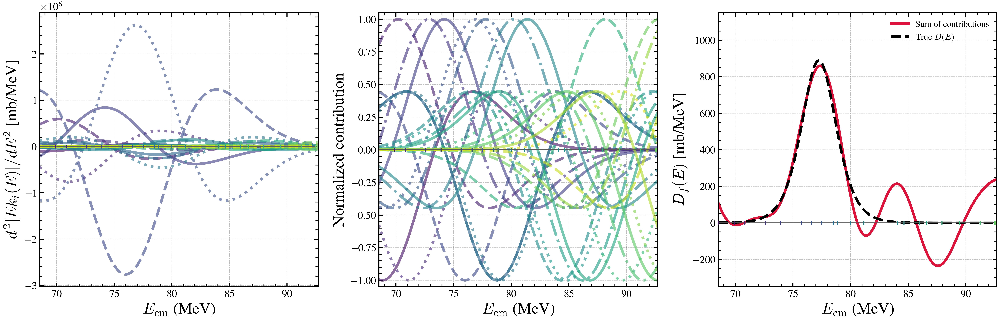

In [97]:
linear_parts, D_decomp_linear, sigma_decomp_linear = derivative_attributions(
    gp_decomp_linear, E_decomp_eval, "linear"
)
_, D_decomp_log, sigma_decomp_log = derivative_attributions(
    gp_decomp_log, E_decomp_eval, "log"
)

fig, axes = plt.subplots(1, 3, figsize=(16.2, 5.35), sharex=True)
colors = plt.cm.viridis(np.linspace(0.05, 0.95, len(E_decomp)))
plot_xmax = E_decomp.max() - 4.0 * np.median(decomp_spacing)


for j, color in enumerate(colors):
    axes[0].plot(E_decomp_eval, linear_parts[:, j], color=color, lw=3, alpha=0.62)
#axes[0].set_title("Individual RBF contributions", pad=10)
axes[0].set_ylabel(r"$d^2[E k_i(E)]/dE^2$ [mb/MeV]")

scales = np.max(np.abs(linear_parts), axis=0)
normalized_parts = np.divide(
    linear_parts,
    scales[None, :],
    out=np.zeros_like(linear_parts),
    where=scales[None, :] > 0,
)
for j, color in enumerate(colors):
    axes[1].plot(E_decomp_eval, normalized_parts[:, j], color=color, lw=3, alpha=0.62)
#axes[1].set_title("Individually normalized", pad=10)
axes[1].set_ylabel("Normalized contribution", )
axes[1].set_ylim(-1.05, 1.05)

axes[2].plot(E_decomp_eval, D_decomp_linear, color="crimson", lw=3, label="Sum of contributions")
axes[2].plot(E_decomp_eval, D_decomp_true, color="black", ls="--", lw=3, label="True $D(E)$")
#axes[2].set_title("Cancellation gives the barrier", pad=10)
axes[2].set_ylabel(r"$D_f(E)$ [mb/MeV]")
axes[2].set_ylim(-350, 1150)
axes[2].legend(loc="upper right", frameon=False, fontsize=10)

for ax in axes:
    ax.scatter(E_decomp, np.zeros_like(E_decomp), c=colors, s=20, marker="|", linewidths=1.2, zorder=5)
    ax.axhline(0, color="0.35", lw=1.0)
    ax.set_xlim(E_decomp.min(), plot_xmax)
    ax.set_xlabel(r"$E_{\mathrm{cm}}$ (MeV)")
    ax.grid(True, alpha=0.25)
    ax.tick_params(axis="both", labelsize=12, width=1.2, length=4.5)
    for spine in ax.spines.values():
        spine.set_linewidth(1.2)

fig.tight_layout(w_pad=1.5)
save_dir = PROJECT_ROOT / "plots"
save_dir.mkdir(exist_ok=True)
fig.savefig(save_dir / "gp_linear_rbf_derivative_decomposition_cv075.pdf", bbox_inches="tight")
fig.savefig(save_dir / "gp_linear_rbf_derivative_decomposition_cv075.png", bbox_inches="tight", dpi=300)
plt.show()


### Experiment 1: increasing measurement noise on a dense grid

This experiment starts from the best-fit Wong cross section and samples it every
0.2 MeV. Synthetic Gaussian noise is added with pointwise standard deviation
$\eta\sigma(E)$. The GP is trained in linear cross-section space with the true
heteroscedastic variances supplied through `alpha`. The saved figure compares
cross-section recovery with the induced barrier distribution. The cross-section
band is the pointwise GP mean plus/minus 1.96 posterior standard deviations; the
barrier band is computed by differentiating posterior cross-section draws and
plotting their sample mean plus/minus 1.96 sample standard deviations.


In [98]:
# RNG for reproducible corruption
rng = np.random.default_rng(0)

# Experiment 1/2: train on a 0.2 MeV grid; true derivatives stay on E_fine.
noise_ratio = [5e-3, 1e-2, 5e-2, 1e-1]#[1e-16, 1e-8, 1e-4, 1e-2]
for ratio in noise_ratio:
    alpha = (ratio * sigma_train_exp12)**2
    sigma_noisy = sigma_train_exp12 + rng.normal(0, np.sqrt(alpha))

    # use ratio in filename (e.g. 0.005 -> "0.005")
    tag = f"{ratio:.3f}"
    if save_data:
        np.save(DATA_DIR / f"E_train_exp12_{tag}.npy", E_train_exp12)
        np.save(DATA_DIR / f"alpha_exp12_{tag}.npy", alpha)
        np.save(DATA_DIR / f"sigma_train_noisy_exp12_{tag}.npy", sigma_noisy)


In [99]:
# PARAMETERS & GRIDS
noise_ratio = [5e-3, 1e-2, 5e-2, 1e-1]#[1e-16, 1e-8, 1e-4, 1e-2]
start = 0

# Create a 0.2 MeV training set for the GP:
E_train = E_train_exp12
sigma_train = sigma_train_exp12
rng = np.random.default_rng(0)

# TRAIN & PREDICT — store in a dict for plotting
results = {}
for i, ratio in enumerate(noise_ratio):
    alpha = (ratio * sigma_train)**2
    sigma_train_noisy = sigma_train + rng.normal(0, np.sqrt(alpha))
    gp = train_gp(E_train, sigma_train_noisy, alpha, n_restarts=gp_n_restarts)
    mu, std = gp.predict(E_eval.reshape(-1, 1), return_std=True)
    samples = gp.sample_y(E_fine.reshape(-1, 1), n_samples=n_samples)
    results[i] = {
        "gp": gp,
        "mu": mu,
        "std": std,
        "samples": samples,
        "barrier_E": E_fine,
        "ratio": ratio,
        "alpha": alpha,
        "E_train": E_train,
        "sigma_train_noisy": sigma_train_noisy,
    }


132331.47660503673


/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 9 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


132700.49421302878


/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 10 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 12 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 6 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html


132598.7310651272


/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 6 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 9 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better va

135161.93342462412


/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 10 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 12 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better 

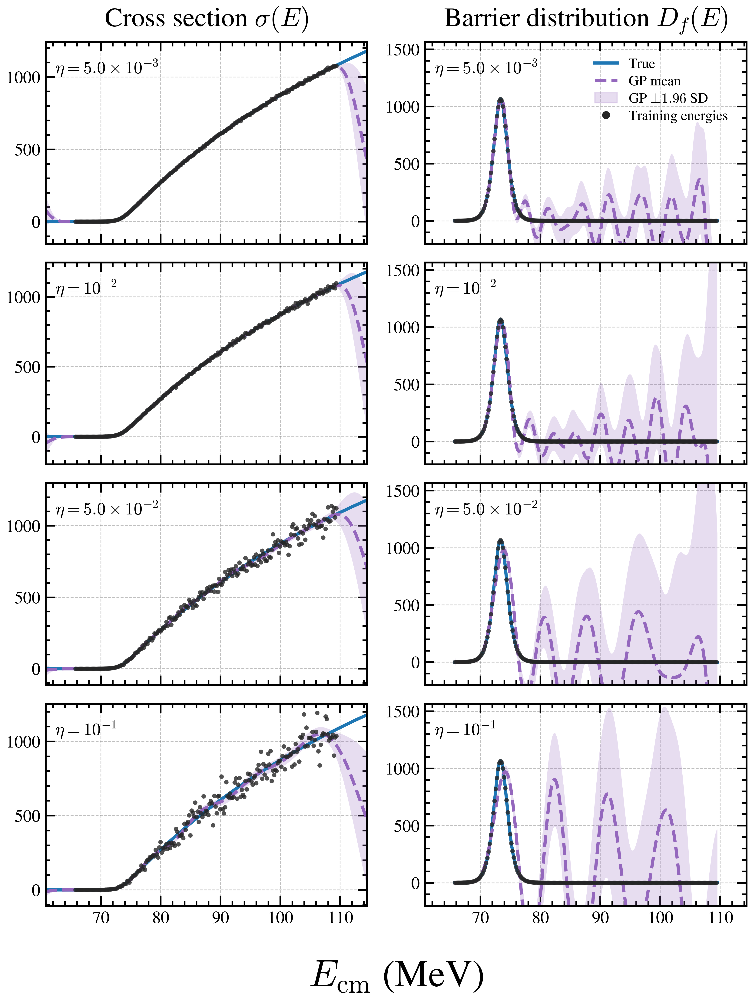

In [100]:
# Plot/export for Experiment 1: noise-level scan.
plot_sigma_barrier_grid(
    results,
    PLOT_DIR / "gp_sigma_and_barrier_grid.png",
    suptitle=None,
)


In [101]:
# This used to save a duplicate of plots/gp_sigma_and_barrier_grid.png under
# plots/gp_sigma_and_barrier_grid_legacy_replacement.png. It adds no new
# content, so the duplicate export is intentionally disabled.


### Experiment 2: adding a fitted white-noise kernel

The training data are the same as Experiment 1, but the kernel includes an
additional `WhiteKernel`. This asks whether learning an extra independent-noise
term stabilizes the derivative when the pointwise noise variances are already
known. The code is left explicit so developers can change the white-noise bounds.
The plotted bands use the same plus/minus 1.96 standard-deviation envelopes as
Experiment 1, not independently calibrated confidence intervals.


In [102]:
# Create the same 0.2 MeV training set for the GP:
E_train = E_train_exp12
sigma_train = sigma_train_exp12
rng = np.random.default_rng(0)

# TRAIN & PREDICT — store in a dict for plotting
results_noise = {}
for i, ratio in enumerate(noise_ratio):
    alpha = (ratio * sigma_train)**2
    sigma_train_noisy = sigma_train + rng.normal(0, np.sqrt(alpha))
    gp = train_gp(E_train, sigma_train_noisy, alpha, n_restarts=gp_n_restarts, noise=True)
    mu, std = gp.predict(E_eval.reshape(-1, 1), return_std=True)
    samples = gp.sample_y(E_fine.reshape(-1, 1), n_samples=n_samples)
    exponent = int(np.log10(ratio))
    results_noise[i] = {
        "gp": gp,
        "mu": mu,
        "std": std,
        "samples": samples,
        "barrier_E": E_fine,
        "exp": exponent,
        "ratio": ratio,
        "alpha": alpha,
        "E_train": E_train,
        "sigma_train_noisy": sigma_train_noisy,
    }


132331.47660503673


/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 22 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 23 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a bet

132700.49421302878


/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 20 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-09. Decreasing the bound and calling fit again may find a better value.
  warnings.warn

132598.7310651272


/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 20 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 22 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 16 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html

135161.93342462412


/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 17 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 21 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a bet

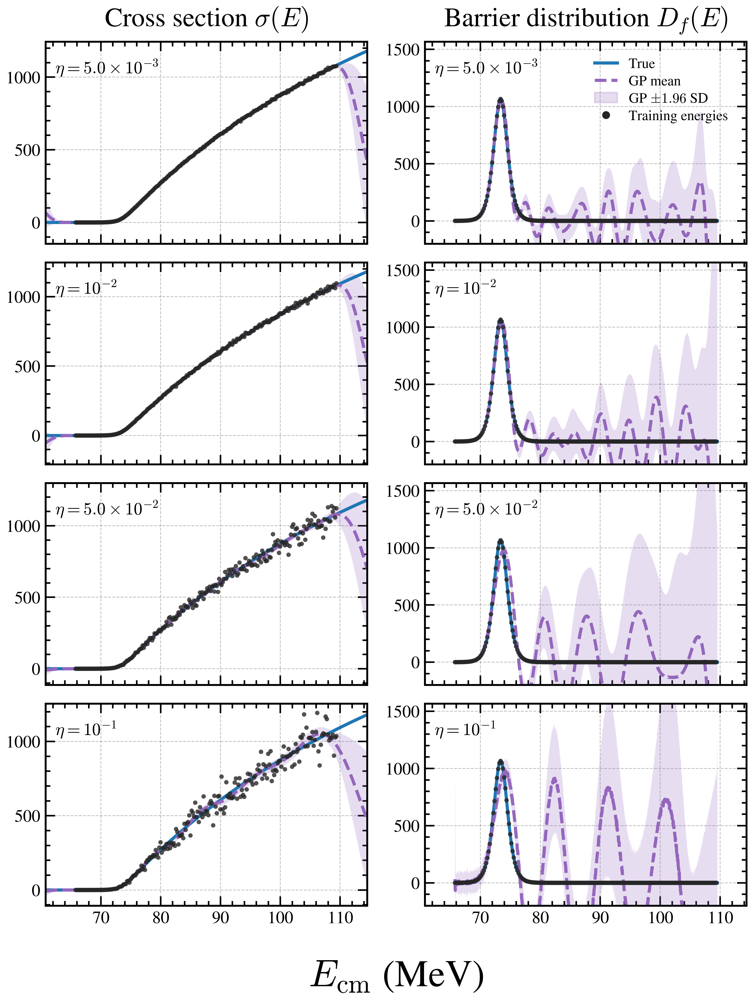

In [103]:
# Plot/export for Experiment 2: fitted white-noise kernel scan.
# Legacy individual noise-kernel exports are now one combined LaTeX-ready figure.
plot_sigma_barrier_grid(
    results_noise,
    PLOT_DIR / "gp_sigma_and_barrier_grid_noise.png",
   # suptitle="RBF kernel with fitted white-noise term",
)


### Experiment 3: energy resolution at fixed relative noise

Here the training grids target average spacings of roughly 0.4, 0.8, 1.2,
and 1.6 MeV. The notebook precomputes and optionally saves these arrays so the
plotting cells can be rerun without regenerating the noisy training sets.


In [104]:
resolution_spacings = [0.4, 0.8, 1.2, 1.6]
rng = np.random.default_rng()


def resolution_spacing_tag(spacing):
    return f"{spacing:.1f}MeV"


for spacing in resolution_spacings:
    # Build a grid with the requested approximate spacing, anchored to E_fine.
    E_tr = np.arange(E_fine.min(), E_fine.max() + 0.5 * spacing, spacing)
    E_tr = E_tr[E_tr <= E_fine.max()]
    E_dist = np.arange(E_tr[0] - 5, E_tr[-1] + 5, 0.2)
    y_tr = sigma(E_tr, E0_opt, R0_opt, hbarw_opt)
    var_tr = (0.1 * y_tr)**2
    y_tr_noisy = y_tr + rng.normal(0, np.sqrt(var_tr))
    var_tr_1e_2 = (0.01 * y_tr)**2
    y_tr_noisy_1e_2 = y_tr + rng.normal(0, np.sqrt(var_tr_1e_2))

    tag = resolution_spacing_tag(spacing)
    print(f"target spacing={spacing:.1f} MeV, average grid spacing={np.diff(E_tr).mean():.3f} MeV, n={len(E_tr)}")
    if save_data:
        np.save(DATA_DIR / f"E_tr_spacing{tag}.npy", E_tr)
        np.save(DATA_DIR / f"E_dist_spacing{tag}.npy", E_dist)
        np.save(DATA_DIR / f"y_tr_noisy_spacing{tag}_1e-1.npy", y_tr_noisy)
        np.save(DATA_DIR / f"y_tr_noisy_spacing{tag}_1e-2.npy", y_tr_noisy_1e_2)
        np.save(DATA_DIR / f"var_tr_spacing{tag}_1e-1.npy", var_tr)
        np.save(DATA_DIR / f"var_tr_spacing{tag}_1e-2.npy", var_tr_1e_2)


target spacing=0.4 MeV, average grid spacing=0.400 MeV, n=110
target spacing=0.8 MeV, average grid spacing=0.800 MeV, n=55
target spacing=1.2 MeV, average grid spacing=1.200 MeV, n=37
target spacing=1.6 MeV, average grid spacing=1.600 MeV, n=28


#### Experiment 3a: coarse grids with $\eta=10^{-1}$

The GP is trained in log space for each energy resolution. Log training enforces
positive cross sections by fitting $\log\sigma$ and using the delta-method
variance `var_tr/y_tr_noisy**2` inside `train_gp`. The plot block at the bottom
compares these fits directly with the lower-noise scan.


In [105]:
# LOAD AND TRAIN
resolution_spacings = [0.4, 0.8, 1.2, 1.6]
barrier_results = {}

log = True
for spacing in resolution_spacings:
    tag = resolution_spacing_tag(spacing)
    E_tr = np.load(DATA_DIR / f"E_tr_spacing{tag}.npy")
    E_dist = np.load(DATA_DIR / f"E_dist_spacing{tag}.npy")
    y_tr_noisy = np.load(DATA_DIR / f"y_tr_noisy_spacing{tag}_1e-1.npy")
    var_tr = np.load(DATA_DIR / f"var_tr_spacing{tag}_1e-1.npy")

    gp = train_gp(E_tr, y_tr_noisy, var_tr, n_restarts=gp_n_restarts, log=log)
    samples = np.exp(gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)) if log else gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)
    barrier_results[spacing] = {
        "E_tr": E_tr,
        "y_tr": y_tr_noisy,
        "var_tr": var_tr,
        "samples": samples,
        "E_dist": E_dist
    }


130664.39449268836
149207.7006157447
147281.6215545238
130450.72178081842


In [106]:
# The eta=10^-1 resolution results are plotted together with eta=10^-2 after both fits are available.


#### Experiment 3b: coarse grids with $\eta=10^{-2}$

This repeats the resolution scan with smaller relative noise. Comparing it to
Experiment 3a separates the effect of sparse energy sampling from the effect of
larger measurement noise.


In [107]:
resolution_spacings = [0.4, 0.8, 1.2, 1.6]
barrier_results_2 = {}

log = True
for spacing in resolution_spacings:
    tag = resolution_spacing_tag(spacing)
    E_tr = np.load(DATA_DIR / f"E_tr_spacing{tag}.npy")
    E_dist = np.load(DATA_DIR / f"E_dist_spacing{tag}.npy")
    y_tr_noisy = np.load(DATA_DIR / f"y_tr_noisy_spacing{tag}_1e-2.npy")
    var_tr = np.load(DATA_DIR / f"var_tr_spacing{tag}_1e-2.npy")

    gp = train_gp(E_tr, y_tr_noisy, var_tr, n_restarts=gp_n_restarts, log=log)
    samples = np.exp(gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)) if log else gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)
    barrier_results_2[spacing] = {
        "E_tr": E_tr,
        "y_tr": y_tr_noisy,
        "var_tr": var_tr,
        "E_dist": E_dist,
        "samples": samples
    }


132652.51354681613
133080.63749266003
134207.4862283665
134386.8049116494


$\eta = 10^{-1}$, $\langle\Delta E\rangle = 0.40\,\mathrm{MeV}$: 3-point stencil=6, average Delta E = 2.40 MeV
$\eta = 10^{-1}$, $\langle\Delta E\rangle = 0.80\,\mathrm{MeV}$: 3-point stencil=3, average Delta E = 2.40 MeV
$\eta = 10^{-1}$, $\langle\Delta E\rangle = 1.20\,\mathrm{MeV}$: 3-point stencil=2, average Delta E = 2.40 MeV
$\eta = 10^{-1}$, $\langle\Delta E\rangle = 1.60\,\mathrm{MeV}$: 3-point stencil=2, average Delta E = 3.20 MeV
$\eta = 10^{-2}$, $\langle\Delta E\rangle = 0.40\,\mathrm{MeV}$: 3-point stencil=6, average Delta E = 2.40 MeV
$\eta = 10^{-2}$, $\langle\Delta E\rangle = 0.80\,\mathrm{MeV}$: 3-point stencil=3, average Delta E = 2.40 MeV
$\eta = 10^{-2}$, $\langle\Delta E\rangle = 1.20\,\mathrm{MeV}$: 3-point stencil=2, average Delta E = 2.40 MeV
$\eta = 10^{-2}$, $\langle\Delta E\rangle = 1.60\,\mathrm{MeV}$: 3-point stencil=2, average Delta E = 3.20 MeV


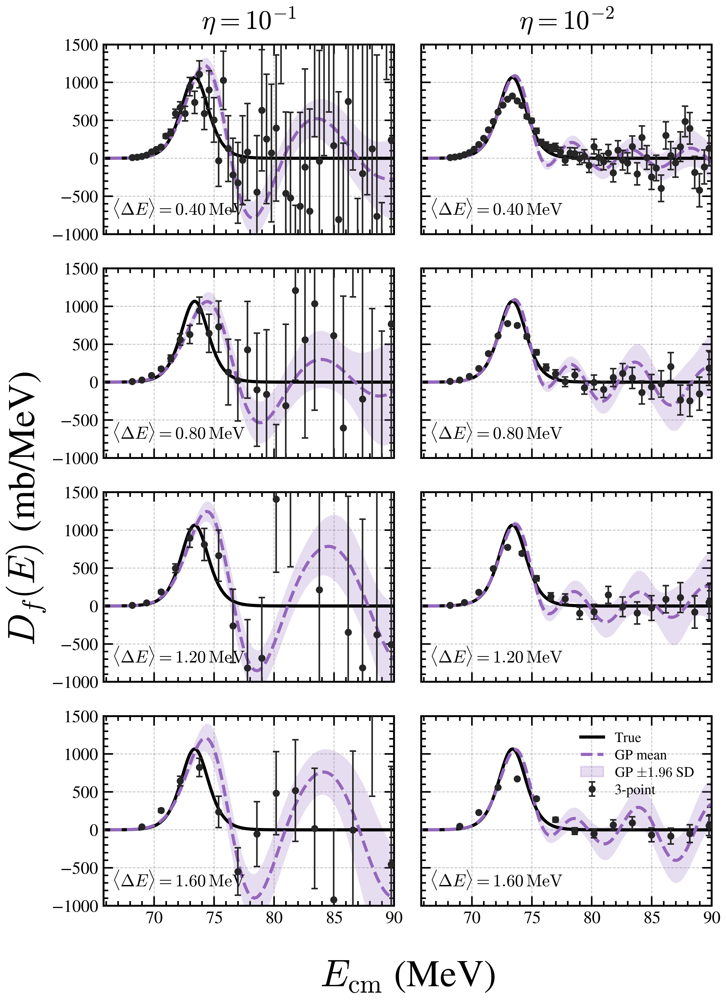

In [108]:
# Plot/export for Experiment 3: resolution comparison.
plot_barrier_comparison_grid(
    [
        (rf"$\eta = 10^{{-1}}$", barrier_results, None),
        (rf"$\eta = 10^{{-2}}$", barrier_results_2, None),
    ],
    PLOT_DIR / "gp_barrier_coarse_grid_noise_comparison.png",
    row_keys=resolution_spacings,
    panel_label_fn=lambda spacing, data: rf"$\langle\Delta E\rangle = {np.diff(data['E_tr']).mean():.2f}\,\mathrm{{MeV}}$",
    suptitle=None,
)


### Experiment 4: irregular energy spacing

The next pair of experiments samples the same underlying curve with random
positive spacings drawn from a clipped normal distribution. The coefficient of
variation controls the degree of irregularity: `cv=0` is uniform spacing, and
larger values create clustered and sparse regions. The first scan fixes the mean
spacing at 0.5 MeV and uses 1% relative cross-section noise.


In [109]:
cv_values    = [0.0, 0.25, 0.5, 0.75]
mean_spacing = 0.5   # MeV
rng          = np.random.default_rng(0)

# find your limits from existing E_fine
stop_idx = -1#np.argmin(np.abs(E_fine - 80.0))
E_min, E_max = E_fine[0], E_fine[stop_idx]

# evaluation grid — save once
E_dist = np.arange(E_min - 5, E_max + 5, 0.2)
if save_data:
    np.save(DATA_DIR / "E_dist_cv.npy", E_dist)

for cv in cv_values:
    std_sp = mean_spacing * cv
    N      = int((E_max - E_min) / mean_spacing) + 5

    # 1) build irregular E_tr
    dE_sim = np.random.normal(mean_spacing, std_sp, size=N)
    dE_sim = np.clip(dE_sim, 1e-3, None)
    E_tr   = E_min + np.cumsum(dE_sim)
    E_tr   = E_tr[E_tr <= E_max]

    # 2) interpolate and corrupt
    y_tr       = np.interp(E_tr, E_fine[:stop_idx], sigma_mean[:stop_idx])
    var_tr     = (0.01 * y_tr)**2
    y_tr_noisy = y_tr + rng.normal(0, np.sqrt(var_tr), size=y_tr.shape)

    tag = f"{cv:.2f}"
    if save_data:
        np.save(DATA_DIR / f"E_tr_cv_{tag}.npy", E_tr)
        np.save(DATA_DIR / f"y_tr_cv_{tag}.npy", y_tr)
        np.save(DATA_DIR / f"var_tr_cv_{tag}.npy", var_tr)
        np.save(DATA_DIR / f"y_tr_noisy_cv_{tag}.npy", y_tr_noisy)



In [110]:
cv_values = [0.0, 0.25, 0.5, 0.75]
mean_spacing = 0.5 # 0.5   # MeV
barrier_results_cv = {}

log=True
for cv in cv_values:
    tag       = f"{cv:.2f}"
    E_tr      = np.load(DATA_DIR / f"E_tr_cv_{tag}.npy")
    y_tr_noisy= np.load(DATA_DIR / f"y_tr_noisy_cv_{tag}.npy")
    var_tr    = np.load(DATA_DIR / f"var_tr_cv_{tag}.npy")

    gp = train_gp(E_tr, y_tr_noisy, var_tr, n_restarts=gp_n_restarts, log=log)
    samples = np.exp(gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)) if log else gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)

    barrier_results_cv[cv] = {
        "E_tr":    E_tr,
        "y_tr":    y_tr_noisy,
        "var_tr":  var_tr,
        "samples": samples
    }

E_dist_cv_05 = E_dist.copy()


131948.07494758777
128879.64171911898
136453.1907845892
137011.27128330388


In [111]:
# The 0.5 MeV irregularity results are plotted together with 1.0 MeV after both fits are available.


#### Experiment 4b: irregular spacing with 1.0 MeV average separation

This repeats the irregular-grid scan with approximately half as many training
points by increasing the mean spacing from 0.5 MeV to 1.0 MeV. The bottom
plotting block compares the two scans directly.


In [112]:
cv_values    = [0.0, 0.25, 0.5, 0.75]
mean_spacing = 1.0   # MeV
rng          = np.random.default_rng(0)

# find your limits from existing E_fine
stop_idx = -1#np.argmin(np.abs(E_fine - 80.0))
E_min, E_max = E_fine[0], E_fine[stop_idx]

# evaluation grid — save once
E_dist = np.arange(E_min - 5, E_max + 5, 0.2)
if save_data:
    np.save(DATA_DIR / "E_dist_cv_1MEV.npy", E_dist)

for cv in cv_values:
    std_sp = mean_spacing * cv
    N      = int((E_max - E_min) / mean_spacing) + 5

    # 1) build irregular E_tr
    dE_sim = np.random.normal(mean_spacing, std_sp, size=N)
    dE_sim = np.clip(dE_sim, 1e-3, None)
    E_tr   = E_min + np.cumsum(dE_sim)
    E_tr   = E_tr[E_tr <= E_max]

    # 2) interpolate and corrupt
    y_tr       = np.interp(E_tr, E_fine[:stop_idx], sigma_mean[:stop_idx])
    var_tr     = (0.01 * y_tr)**2
    y_tr_noisy = y_tr + rng.normal(0, np.sqrt(var_tr), size=y_tr.shape)

    tag = f"{cv:.2f}"
    if save_data:
        np.save(DATA_DIR / f"E_tr_cv_{tag}_1MEV.npy", E_tr)
        np.save(DATA_DIR / f"y_tr_cv_{tag}_1MEV.npy", y_tr)
        np.save(DATA_DIR / f"var_tr_cv_{tag}_1MEV.npy", var_tr)
        np.save(DATA_DIR / f"y_tr_noisy_cv_{tag}_1MEV.npy", y_tr_noisy)

In [113]:
cv_values = [0.0, 0.25, 0.5, 0.75]
mean_spacing = 1.0 # 0.5   # MeV
barrier_results_cv_2 = {}

log=True
for cv in cv_values:
    tag       = f"{cv:.2f}"
    E_tr      = np.load(DATA_DIR / f"E_tr_cv_{tag}_1MEV.npy")
    y_tr_noisy= np.load(DATA_DIR / f"y_tr_noisy_cv_{tag}_1MEV.npy")
    var_tr    = np.load(DATA_DIR / f"var_tr_cv_{tag}_1MEV.npy")

    gp = train_gp(E_tr, y_tr_noisy, var_tr, n_restarts=gp_n_restarts, log=log)
    samples = np.exp(gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)) if log else gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)

    barrier_results_cv_2[cv] = {
        "E_tr":    E_tr,
        "y_tr":    y_tr_noisy,
        "var_tr":  var_tr,
        "samples": samples
    }

E_dist_cv_10 = E_dist.copy()


130731.25821889406
126437.08959421373
133790.5694005207
116880.28445050489


$\langle\Delta E\rangle = 0.50\,\mathrm{MeV}$, $\kappa = 0.00$: 3-point stencil=5, average Delta E = 2.50 MeV
$\langle\Delta E\rangle = 0.50\,\mathrm{MeV}$, $\kappa = 0.25$: 3-point stencil=5, average Delta E = 2.63 MeV
$\langle\Delta E\rangle = 0.50\,\mathrm{MeV}$, $\kappa = 0.50$: 3-point stencil=5, average Delta E = 2.50 MeV
$\langle\Delta E\rangle = 0.50\,\mathrm{MeV}$, $\kappa = 0.75$: 3-point stencil=5, average Delta E = 2.53 MeV
$\langle\Delta E\rangle = 1.00\,\mathrm{MeV}$, $\kappa = 0.00$: 3-point stencil=2, average Delta E = 2.00 MeV
$\langle\Delta E\rangle = 1.00\,\mathrm{MeV}$, $\kappa = 0.25$: 3-point stencil=3, average Delta E = 2.93 MeV
$\langle\Delta E\rangle = 1.00\,\mathrm{MeV}$, $\kappa = 0.50$: 3-point stencil=3, average Delta E = 2.76 MeV
$\langle\Delta E\rangle = 1.00\,\mathrm{MeV}$, $\kappa = 0.75$: 3-point stencil=3, average Delta E = 2.63 MeV


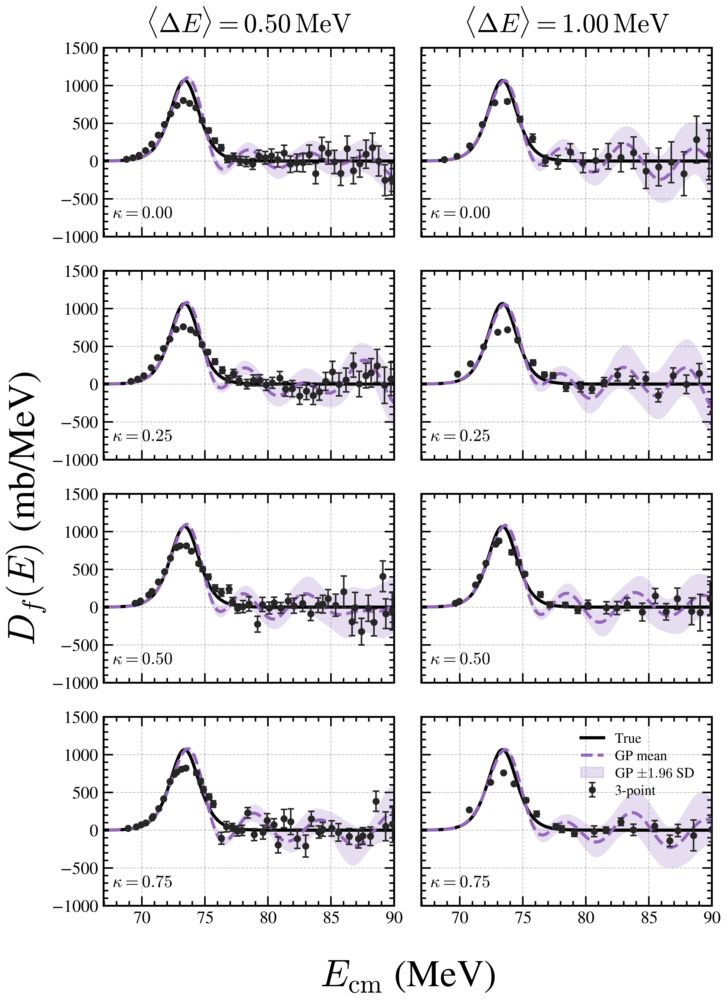

In [114]:
# Plot/export for Experiment 4: irregular-spacing comparison.
plot_barrier_comparison_grid(
    [
        (rf"$\langle\Delta E\rangle = 0.50\,\mathrm{{MeV}}$", barrier_results_cv, lambda cv, data: E_dist_cv_05),
        (rf"$\langle\Delta E\rangle = 1.00\,\mathrm{{MeV}}$", barrier_results_cv_2, lambda cv, data: E_dist_cv_10),
    ],
    PLOT_DIR / "gp_barrier_cv_grid_spacing_comparison.png",
    row_keys=cv_values,
    panel_label_fn=lambda cv, data: rf"$\kappa = {cv:.2f}$",
    suptitle=None,
)


## Experiment 5: missing quoted uncertainties with known truth

This controlled benchmark asks what to do when the energy points are known but
pointwise experimental uncertainties are not. The code profiles over a grid of
constant relative-error values and chooses the error scale that maximizes the GP
marginal likelihood on that grid. The comparison is run in both linear space and
log space, then judged against the known synthetic barrier.


In [ ]:
def fit_profiled_relative_error_gp(E, y, space, eta_grid=None, random_state=0):
    """Profile one unknown constant relative uncertainty eta by GP marginal likelihood."""
    E = np.asarray(E, float)
    y = np.asarray(y, float)
    order = np.argsort(E)
    E, y = E[order], y[order]
    spacing = np.diff(E)
    ell0 = 2.0*np.median(spacing)
    ell_bounds = (0.5*np.median(spacing), max(10.0, 10.0*np.median(spacing)))

    if eta_grid is None:
        eta_grid = np.geomspace(0.003, 0.30, 14)
    if space == "log" and np.any(y <= 0):
        raise ValueError("Log-space approximation requires positive measurements.")

    profile = []
    for eta in np.asarray(eta_grid, float):
        if space == "linear":
            target = y
            sigma_scale = np.maximum(np.abs(y), 1e-12*np.max(y))
            gp = None
            # Feasible heteroscedastic GP: update the unknown sigma_i entering
            # Var(Y_i|sigma_i)=eta^2*sigma_i^2 from the current smooth fit.
            for _ in range(2):
                signal = ConstantKernel(max(np.var(target), 1e-6), (1e-8, 1e10)) * RBF(
                    ell0, ell_bounds
                )
                gp = GaussianProcessRegressor(
                    kernel=signal,
                    alpha=np.maximum((eta*sigma_scale)**2, 1e-14),
                    normalize_y=False,
                    n_restarts_optimizer=0,
                    random_state=random_state,
                ).fit(E[:, None], target)
                sigma_scale = np.maximum(gp.predict(E[:, None]), 1e-12*np.max(y))
        elif space == "log":
            target = np.log(y) + 0.5*eta**2
            signal = ConstantKernel(max(np.var(target), 1e-6), (1e-8, 1e10)) * RBF(
                ell0, ell_bounds
            )
            gp = GaussianProcessRegressor(
                kernel=signal,
                alpha=np.full(len(E), eta**2),
                normalize_y=False,
                n_restarts_optimizer=0,
                random_state=random_state,
            ).fit(E[:, None], target)
        else:
            raise ValueError("space must be 'linear' or 'log'")
        profile.append((eta, gp.log_marginal_likelihood_value_, gp))

    learned_eta, _, best_gp = max(profile, key=lambda item: item[1])
    profile_df = pd.DataFrame({
        "eta": [item[0] for item in profile],
        "log_marginal_likelihood": [item[1] for item in profile],
    })
    return best_gp, float(learned_eta), profile_df


def physical_sigma_from_gp(gp, X, space):
    latent = gp.predict(np.asarray(X)[:, None])
    return latent if space == "linear" else np.exp(latent)


def physical_draws_from_gp(gp, X, space, n_draws, random_state):
    latent = gp.sample_y(
        np.asarray(X)[:, None], n_samples=n_draws, random_state=random_state
    ).T
    return latent if space == "linear" else np.exp(latent)


: 

In [ ]:
from IPython.display import display

# Difficult grid from Experiment 4: CV=0.75 and mean spacing 1 MeV.
E_missing = np.sort(np.load(DATA_DIR / "E_tr_cv_0.75_1MEV.npy"))
sigma_missing_true = sigma(E_missing, E0_opt, R0_opt, hbarw_opt)
E_missing_eval = np.linspace(E_missing.min(), E_missing.max(), 260)
sigma_missing_eval_true = sigma(E_missing_eval, E0_opt, R0_opt, hbarw_opt)
D_missing_true = barrier_dist(E_missing_eval, sigma_missing_eval_true, acc=4)
barrier_active_mask = D_missing_true >= 0.01*np.max(D_missing_true)
true_peak_index = np.argmax(D_missing_true[barrier_active_mask])
true_peak_E = E_missing_eval[barrier_active_mask][true_peak_index]
true_peak_height = D_missing_true[barrier_active_mask][true_peak_index]

fractional_errors = np.array([0.01, 0.03, 0.05, 0.10])
n_repetitions = 8
n_posterior_draws = 50
benchmark_rows = []
representative_cases = {}

for error_index, true_fractional_error in enumerate(fractional_errors):
    for repetition in range(n_repetitions):
        seed = 10000*error_index + repetition
        rng = np.random.default_rng(seed)
        observed = sigma_missing_true + rng.normal(
            0.0, true_fractional_error*sigma_missing_true, len(E_missing)
        )
        if np.any(observed <= 0):
            # This is extraordinarily unlikely for eta <= 0.1, but the log
            # approximation is undefined for a non-positive realization.
            continue

        case = {"E": E_missing, "observed": observed}
        for model_index, space in enumerate(["linear", "log"]):
            gp, learned_error, eta_profile = fit_profiled_relative_error_gp(
                E_missing, observed, space,
                random_state=seed + 1000*model_index,
            )
            sigma_fit = physical_sigma_from_gp(gp, E_missing_eval, space)
            D_fit = barrier_dist(E_missing_eval, sigma_fit, acc=4)
            sigma_draws = physical_draws_from_gp(
                gp, E_missing_eval, space,
                n_draws=n_posterior_draws,
                random_state=seed + 2000*model_index,
            )
            D_draws = np.asarray([
                barrier_dist(E_missing_eval, draw, acc=4)
                for draw in sigma_draws
            ])
            # Central 68% pointwise envelope from differentiated posterior draws.
            lo68, hi68 = np.percentile(D_draws, [16, 84], axis=0)
            benchmark_rows.append({
                "true_fractional_error": true_fractional_error,
                "repetition": repetition,
                "space": space,
                "learned_error": learned_error,
                "sigma_log_RMSE": np.sqrt(np.mean((
                    np.log(np.maximum(sigma_fit, 1e-300))
                    - np.log(sigma_missing_eval_true)
                )**2)),
                "barrier_RMSE": np.sqrt(np.mean((D_fit - D_missing_true)**2)),
                "active_barrier_RMSE": np.sqrt(np.mean((
                    D_fit[barrier_active_mask] - D_missing_true[barrier_active_mask]
                )**2)),
                "peak_location_error": abs(
                    E_missing_eval[barrier_active_mask][np.argmax(D_fit[barrier_active_mask])]
                    - true_peak_E
                ),
                "peak_height_relative_error": abs(
                    np.max(D_fit[barrier_active_mask]) - true_peak_height
                ) / true_peak_height,
                "barrier_68_coverage": np.mean(
                    (D_missing_true[barrier_active_mask] >= lo68[barrier_active_mask])
                    & (D_missing_true[barrier_active_mask] <= hi68[barrier_active_mask])
                ),
            })
            case[space] = {
                "sigma_fit": sigma_fit, "D_fit": D_fit,
                "D_lo": lo68, "D_hi": hi68,
                "learned_error": learned_error,
                "kernel": str(gp.kernel_),
                "eta_profile": eta_profile,
            }
        if repetition == 0:
            representative_cases[true_fractional_error] = case

benchmark_df = pd.DataFrame(benchmark_rows)
benchmark_summary = benchmark_df.groupby(
    ["true_fractional_error", "space"]
).agg(
    learned_error_median=("learned_error", "median"),
    sigma_log_RMSE_median=("sigma_log_RMSE", "median"),
    barrier_RMSE_median=("barrier_RMSE", "median"),
    barrier_RMSE_q25=("barrier_RMSE", lambda x: x.quantile(0.25)),
    barrier_RMSE_q75=("barrier_RMSE", lambda x: x.quantile(0.75)),
    active_barrier_RMSE_median=("active_barrier_RMSE", "median"),
    active_barrier_RMSE_q25=("active_barrier_RMSE", lambda x: x.quantile(0.25)),
    active_barrier_RMSE_q75=("active_barrier_RMSE", lambda x: x.quantile(0.75)),
    peak_location_error_median=("peak_location_error", "median"),
    peak_height_relative_error_median=("peak_height_relative_error", "median"),
    barrier_68_coverage_median=("barrier_68_coverage", "median"),
).reset_index()
display(benchmark_summary)


/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/mnt/home/philipaa/envs/plotting/l

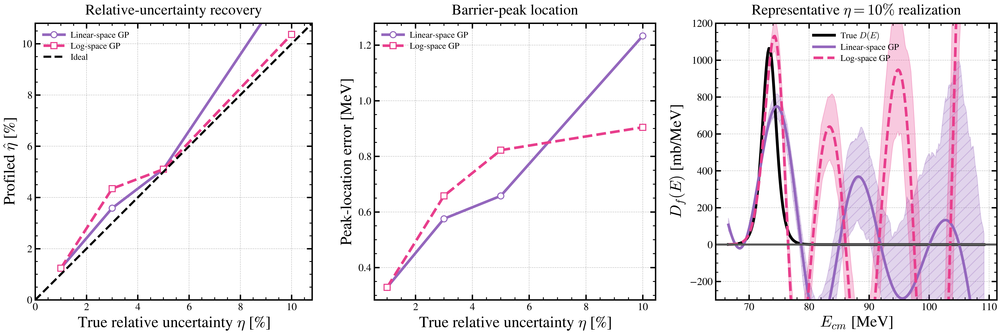

In [ ]:
# Plot/export for Experiment 5: missing-uncertainty benchmark.

fig, axes = plt.subplots(1, 3, figsize=(16.2, 5.55))
PINK_COLOR = "#e83e8c"
model_colors = {"linear": GP_COLOR, "log": PINK_COLOR}
model_linestyles = {"linear": "-", "log": "--"}
model_markers = {"linear": "o", "log": "s"}
model_hatches = {"linear": "//", "log": None}
model_labels = {"linear": "Linear-space GP", "log": "Log-space GP"}
comparison_band_alpha = 0.28
line_width = 3.0
truth_line_width = 3.2
reference_line_width = 2.4
marker_size = 7.0
marker_edge_width = 1.2
band_edge_width = 0.9
axis_line_width = 1.6
tick_width = 1.6
tick_length = 6.0
legend_frame_width = 1.2
legend_handle_length = 2.4


def thicken_legend(ax):
    legend = ax.legend(
        frameon=False,
        handlelength=legend_handle_length,
        handletextpad=0.7,
        borderpad=0.45,
        labelspacing=0.35,
    )
    return legend


# (a) Parity plot for the profiled common relative uncertainty.
for space in ["linear", "log"]:
    data = benchmark_summary.query("space == @space").sort_values("true_fractional_error")
    x = 100*data["true_fractional_error"].to_numpy()
    axes[0].plot(
        x, 100*data["learned_error_median"],
        marker=model_markers[space], ms=marker_size, mew=marker_edge_width,
        mec=model_colors[space], mfc="white", ls=model_linestyles[space],
        lw=line_width, color=model_colors[space], label=model_labels[space],
    )
    axes[1].plot(
        x, data["peak_location_error_median"],
        marker=model_markers[space], ms=marker_size, mew=marker_edge_width,
        mec=model_colors[space], mfc="white", ls=model_linestyles[space],
        lw=line_width, color=model_colors[space], label=model_labels[space],
    )

parity_limit = 100*max(fractional_errors)*1.08
axes[0].plot([0, parity_limit], [0, parity_limit], "k--", lw=reference_line_width, label="Ideal")
axes[0].set_xlim(0, parity_limit)
axes[0].set_ylim(0, parity_limit)
axes[0].set_aspect("equal", adjustable="box")
axes[0].set_xlabel(r"True relative uncertainty $\eta$ [%]")
axes[0].set_ylabel(r"Profiled $\hat{\eta}$ [%]")
axes[0].set_title("Relative-uncertainty recovery", pad=10)
thicken_legend(axes[0])

# (b) Peak-location error.
axes[1].set_xlabel(r"True relative uncertainty $\eta$ [%]")
axes[1].set_ylabel("Peak-location error [MeV]")
axes[1].set_title("Barrier-peak location", pad=10)
thicken_legend(axes[1])

# (c) Representative barrier-distribution reconstruction. Shaded regions are
# central 68% pointwise envelopes from differentiated posterior draws.
example_error = 0.10
example = representative_cases[example_error]
axes[2].plot(E_missing_eval, D_missing_true, color="black", lw=truth_line_width, label="True $D(E)$")
for space in ["linear", "log"]:
    result = example[space]
    axes[2].fill_between(
        E_missing_eval, result["D_lo"], result["D_hi"],
        color=model_colors[space], alpha=comparison_band_alpha,
        hatch=model_hatches[space], edgecolor=model_colors[space], linewidth=band_edge_width,
    )
    axes[2].plot(
        E_missing_eval, result["D_fit"],
        color=model_colors[space], lw=line_width,
        ls=model_linestyles[space], label=model_labels[space],
    )
axes[2].axhline(0, color="0.35", lw=reference_line_width)
axes[2].set_title(r"Representative $\eta=10\%$ realization", pad=10)
axes[2].set_xlabel(r"$E_{cm}$ [MeV]")
axes[2].set_ylabel(r"$D_f(E)$ [mb/MeV]")
axes[2].set_ylim(-300, 1200)
thicken_legend(axes[2])

for ax in axes:
    ax.grid(True, alpha=0.25)
    ax.tick_params(axis="both", labelsize=12, width=tick_width, length=tick_length)
    for spine in ax.spines.values():
        spine.set_linewidth(axis_line_width)

fig.tight_layout(w_pad=1.4)
fig.savefig(PLOT_DIR / "gp_known_truth_missing_errors_linear_vs_log.pdf", bbox_inches="tight")
fig.savefig(PLOT_DIR / "gp_known_truth_missing_errors_linear_vs_log.png", bbox_inches="tight", dpi=300)
plt.show()
plt.close(fig)


### Interpretation of the known-truth benchmark

The data in this benchmark are generated from the same additive Gaussian relative-error model used in the earlier experiments. Both fits profile over the same grid of candidate constant values of $\eta$; the linear fit uses two feasible-GLS updates of the heteroscedastic variances $(\eta\hat\sigma_i)^2$, while the log fit uses the approximation $\log Y_i+\eta^2/2\sim N(\log\sigma_i,\eta^2)$.

On this benchmark, both parameterizations recover the hidden relative uncertainty to the right scale: median profiled values are approximately 0.87%--1.05%, 3.58%, 5.10%, and 10.37% for true values of 1%, 3%, 5%, and 10%. This confirms that the profile-likelihood procedure can estimate the missing common uncertainty without being told $\eta$.

The log-space fit is **not uniformly better** in barrier RMSE on this difficult grid. Linear space has lower median full-barrier RMSE in every row of the saved summary table, while log space has lower median active-barrier RMSE at 3% and 5%. Log space recovers barrier height more accurately: its median peak-height error is about 2%--7%, versus about 6%--28% in linear space. At 3%, 5%, and 10% noise it also gives the better peak location. Thus log space helps the physically important peak amplitude, but can create stronger secondary oscillations that penalize whole-region RMSE.

The central 68% derivative envelopes still omit uncertainty in the selected $\eta$ and optimized kernel hyperparameters, and both methods severely under-cover the true barrier distribution. Estimating a common relative error solves the missing-error pathology, but by itself does not regularize the second derivative sufficiently on this sparse irregular grid.

The comparison should be judged primarily by barrier RMSE and coverage, not by visual smoothness alone. In either space, keeping the fitted noise in `alpha` during the latent refit is essential; directly differentiating draws from a GP that still contains a `WhiteKernel` reproduces the pathological grid-scale noise seen in the experimental notebook.


### Big Picture Conclusions: 

- In these controlled scans, the GP barrier reconstruction begins to degrade as the relative cross-section error moves from $10^{-2}$ toward $10^{-1}$. 
- Adding a fitted `WhiteKernel` has little effect in these runs because the supplied heteroscedastic `alpha` already accounts for the pointwise noise and the optimizer drives the extra white-noise level small. 

- At the tested coarse resolutions, the barrier can still be recovered from sparse data when the relative noise is around $10^{-2}$.

- Irregularity is quantified by the coefficient of variation of the energy step sizes. In the low-noise scans, even highly irregular grids can still capture the barrier height and location reasonably well. 